# Hiệu chỉnh đánh giá phát âm trên checkpoint B đã đóng băng

**Không train thêm wav2vec2/Qwen.** Audio → posterior CTC của B → so sánh các cách phát âm CMU đã công bố → score theo từ → đúng / cần luyện / chưa đủ bằng chứng.
Đây là score âm học tương đối, **không phải xác suất người học phát âm sai**. Không đưa audio, nhãn gold hoặc kết quả vào Qwen.

Pilot được khóa **trước suy luận**: 10 HJK + 10 LXC để fit ngưỡng; 20 PNV để audit ngưỡng đã khóa.
PNV khác speaker với tập fit nhưng cả 450 validation từng dùng chọn checkpoint B; chưa phải kết quả test độc lập.
Run All đọc kết quả đã lưu. Các cell suy luận/hiệu chỉnh có cờ mặc định **False**. Test 900 và SpeechOcean không tự chạy.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Audio, Image, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'scripts/experiment_pronunciation_calibration.py').exists())
os.chdir(ROOT)
for path in (ROOT, ROOT/'src'):
    if str(path) not in sys.path: sys.path.insert(0, str(path))
from scripts import experiment_pronunciation_calibration as experiment
CONFIG = experiment.load_config()
OUTPUT = ROOT/CONFIG['output_root']/'pilot'
PYTHON = ROOT/('.venv/Scripts/python.exe' if os.name=='nt' else '.venv/bin/python')
plan = experiment.prepare(CONFIG, OUTPUT, 'pilot')
print('Python:', PYTHON)
print('Checkpoint:', CONFIG['checkpoint'])
print('Frozen selection:', plan['selection_sha256'])
print('Mode: calibration only; model weights stay unchanged')

Python: D:\NCC\MDD\.venv\Scripts\python.exe
Checkpoint: runs/cascade-l2arctic-plus-seed42/B/best_checkpoint
Frozen selection: eeee0a3441c3bb85ab59b5f0a49bb007a5b81dd75cadc945162e80d1bda99c72
Mode: calibration only; model weights stay unchanged


## 1. Audit dữ liệu và split

Nhãn từ sai lấy từ **annotation âm vị thủ công của L2-ARCTIC**, gồm thay/bỏ/thêm âm. Từ không có lỗi là đối chứng âm tính.
Không sử dụng feedback GPT của L2-Arctic-plus làm nhãn âm học. Word timing/gold/perceived phones chỉ nằm ở phía chấm điểm sau suy luận.
Split gốc 2.249 train / 450 validation / 900 test giữ nguyên; pilot lấy mẫu bằng SHA256 ID, không lọc theo model thắng/thua.

In [2]:
audit = pd.DataFrame(experiment.data_audit(CONFIG, plan))
display(audit.groupby(['role','speaker_id']).agg(
    utterances=('utterance_id','count'), seconds=('duration_sec','sum'),
    words=('words','sum'), correct_words=('gold_correct','sum'),
    error_words=('gold_errors','sum'), unavailable_gold=('gold_unavailable','sum')))
display(pd.DataFrame([plan['split_counts']]))
print('No overlapping fit / heldout speakers:',
      not set(CONFIG['fit_speakers']) & set(CONFIG['heldout_speakers']))
print('Test audio/gold used in this pilot:', plan['test_audio_or_gold_used'])
print('Checkpoint SHA256:', plan['identity']['checkpoint_sha256'])

utterances    seconds  words  correct_words  error_words  \
role    speaker_id                                                             
fit     HJK                 10  33.207234     95             61           34   
        LXC                 10  42.776168     96             35           52   
heldout PNV                 20  75.993855    192             97           95   

                    unavailable_gold  
role    speaker_id                    
fit     HJK                        0  
        LXC                        9  
heldout PNV                        0

,train,validation,test
0,2249,450,900


No overlapping fit / heldout speakers: True
Test audio/gold used in this pilot: False
Checkpoint SHA256: da000521b31ad4d7445b8eb13d82d8a767d6535e678d727aae9baa8a8b177110


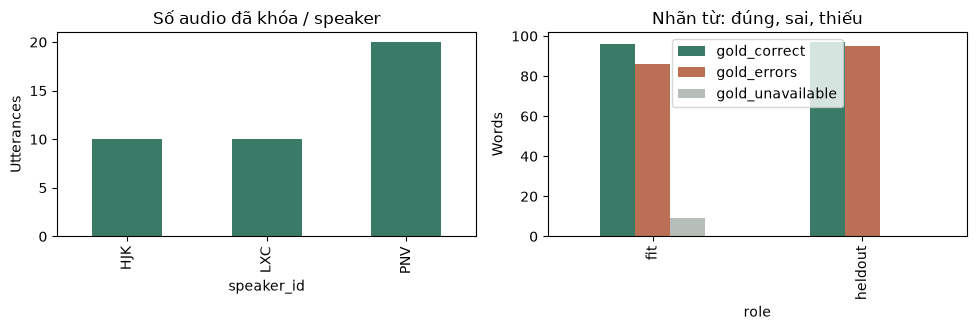

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
audit.groupby('speaker_id')['utterance_id'].count().plot.bar(ax=axes[0], color='#397b67')
axes[0].set_title('Số audio đã khóa / speaker'); axes[0].set_ylabel('Utterances')
audit.groupby('role')[['gold_correct','gold_errors','gold_unavailable']].sum().plot.bar(
    ax=axes[1], color=['#397b67','#bb7056','#b7beb8'])
axes[1].set_title('Nhãn từ: đúng, sai, thiếu'); axes[1].set_ylabel('Words')
fig.tight_layout(); fig.savefig(OUTPUT/'notebook_data_audit.png', dpi=150)
plt.show()

## 2. Nghe audio và xem câu chuẩn

Ví dụ đầu tiên theo selection đã khóa, không chọn theo chất lượng output. Câu đọc được cung cấp như intended reference;
phép thử này chưa đo lỗi ASR trong hội thoại tự do. Metadata của nhãn không đi vào mạng audio hoặc scorer.

In [4]:
first = plan['records'][0]
annotations = experiment.selected_annotations(CONFIG, plan)
example = annotations[first['utterance_id']]
print(first['utterance_id'], first['role'])
print('Reference:', example['prompt_text'])
display(Audio(filename=str(ROOT/first['audio_path'])))
print('Manual error events (evaluation labels only):')
display(pd.DataFrame(example['gold_error_events'])[['kind','expected_phone','observed_phone','word_index']]
        if example['gold_error_events'] else pd.DataFrame())

HJK/arctic_a0028 fit
Reference: Robbery bribery fraud


Manual error events (evaluation labels only):


,kind,expected_phone,observed_phone,word_index
0,substitution,AO,AW,2


## 3. Các cách phát âm được chấp nhận trước khi nhận audio

CMU dictionary đóng băng cung cấp nhiều biến thể. Không đoán từ gần giống, không dùng model âm thanh để tự sửa câu chuẩn.
Ví dụ có thể có các cách đọc khác nhau của `read`, `wind`, `the`. Chấp nhận biến thể từ điển không đồng nghĩa bao phủ mọi giọng hoặc mọi phát âm trong ngữ cảnh.

In [5]:
from mdd.pronunciation_assessment import accepted_variants
variants = accepted_variants(ROOT, 'the read wind')
display(pd.DataFrame([{'word': word['text'], 'available': word['available'],
                      'accepted_phones': [' '.join(v['phones']) for v in word['variants']]}
                     for word in variants]))

,word,available,accepted_phones
0,the,True,"[DH AH, DH IY]"
1,read,True,"[R EH D, R IY D]"
2,wind,True,"[W AY N D, W IH N D]"


## 4. Suy luận B trên CPU — thao tác riêng

B chỉ nhận audio. Scorer sau mạng nhận text chuẩn + CMU + posterior; không nhận nhãn perceived/gold hoặc word timing thủ công.
Posterior được cache riêng theo ID và kiểm tra hash audio/checkpoint/vocabulary. Chạy lại không cần suy luận lại audio đã cache đúng identity.

In [6]:
RUN_INFERENCE = False  # Chủ động đổi True để suy luận pilot 40; không train.
if RUN_INFERENCE:
    subprocess.run([str(PYTHON), '-u', 'scripts/experiment_pronunciation_calibration.py',
                    '--pilot', '--infer'], cwd=ROOT, check=True)
else:
    print('Không chạy model trong cell này. Đọc cache/result có sẵn ở:', OUTPUT)
print('Inference metadata:')
display(experiment.read_json(OUTPUT/'inference.json') if (OUTPUT/'inference.json').exists()
        else {'status':'pending; run the inference cell manually'})

Không chạy model trong cell này. Đọc cache/result có sẵn ở: D:\NCC\MDD\data\generated\pronunciation-calibration-v1\pilot
Inference metadata:


{'utterances': 40,
 'elapsed_sec': 23.875,
 'selection_sha256': 'eeee0a3441c3bb85ab59b5f0a49bb007a5b81dd75cadc945162e80d1bda99c72',
 'identity': {'protocol_sha256': '8692ddd427c5d99829c1997f255dd424ce455a8d63edec19004a09da9125f575',
  'splits_sha256': 'a30deae1afdee02e103408d5e724617e1d3d26e0a642d4e0771a1849b0840fdf',
  'annotations_sha256': '698044c9a8663fa10b91bd264dcfafe8203533270af142f849951bae87617343',
  'checkpoint_sha256': 'da000521b31ad4d7445b8eb13d82d8a767d6535e678d727aae9baa8a8b177110',
  'vocabulary_sha256': '1ebdf682aa547489a70aa72606a3f32fa38398a12977b978b2d874dac3d6bb8d',
  'dictionary_sha256': '81917843c7f44ce2b094ac63873c2c7a4cf802040792c455ba3ca406891c3d22',
  'method': 'ctc_variant_posterior_margin_v1',
  'protocol_id': 'l2arctic-plus-cascade-v1'},
 'method_sha256': 'ce00d0d4a83ca5171bc280732509ae6d6b34b82d34174307b8c6e5f5a8c9c944',
 'network_inputs': 'audio only',
 'scorer_inputs': 'intended text + frozen CMU variants + audio posterior; no manual word times or perce

## 5. Fit ngưỡng trên HJK/LXC, khóa rồi audit PNV

`accept_threshold` thấp → nhận là khớp; `error_threshold` cao → nghi lỗi; ở giữa hoặc score không đủ tin cậy → **uncertain**.
Ngưỡng fit chỉ nhìn 20 audio HJK/LXC. Điều kiện FPR/FNR/coverage/đủ số quyết định đã đăng ký trong config trước suy luận.
Nếu không có ngưỡng đạt, hoặc PNV không đạt điều kiện, artifact **ineligible** và demo tiếp tục uncertain; không tự tuyên bố đã hiệu chỉnh thành công.

In [7]:
display(CONFIG['threshold_policy'])
RUN_CALIBRATION = False  # Fit ngưỡng, không cập nhật trọng số neural model.
if RUN_CALIBRATION:
    subprocess.run([str(PYTHON), 'scripts/experiment_pronunciation_calibration.py',
                    '--pilot', '--calibrate'], cwd=ROOT, check=True)
    subprocess.run([str(PYTHON), 'scripts/experiment_pronunciation_calibration.py',
                    '--pilot', '--report'], cwd=ROOT, check=True)
artifact = experiment.read_json(OUTPUT/'calibration.json') if (OUTPUT/'calibration.json').exists() else None
if artifact:
    display({k: artifact[k] for k in ['status','eligible','experimental','accept_threshold','error_threshold']})
    print('Audit failures:', artifact['validation']['failures'])
else:
    print('Pending: no thresholds have been fitted.')

{'positive_class': 'manually annotated word has at least one substitution, deletion, or addition',
 'max_false_positive_rate': 0.1,
 'max_false_negative_rate': 0.2,
 'min_coverage': 0.5,
 'min_correct_decisions': 10,
 'min_error_decisions': 5,
 'grid_points': 31,
 'objective': 'maximize labelled-word decision coverage subject to registered FPR/FRR and decision-count constraints; tie-break by decided F1'}

{'status': 'ineligible',
 'eligible': False,
 'experimental': True,
 'accept_threshold': None,
 'error_threshold': None}

Audit failures: ['no_threshold_meets_fit_policy']


## 6. Đối chứng trước/sau cách chấm, cùng trọng số B

**Strict:** CTC greedy + một cách đọc CMU đầu tiên + alignment, như baseline cũ.
**Candidate:** score các biến thể + ngưỡng đã fit, vẫn hiển thị để phân tích nếu artifact không đủ điều kiện.
**Safe:** chỉ ra quyết định khi artifact đủ điều kiện; nếu không thì abstain.

Positive = từ có lỗi thủ công. FPR = FP/(FP+TN) trên từ đúng đã ra quyết định; FNR = FN/(TP+FN) trên từ sai đã ra quyết định.
Với cách gọi vận hành, **false rejection FRR = FPR** (báo sai từ vốn đúng), **false acceptance FAR = FNR** (chấp nhận từ vốn sai).
Xem thêm `recall_all_errors` và `coverage`: không che các từ bị abstain bằng cách chỉ báo cáo accuracy trên phần dễ.

,role,system,tp,fp,tn,fn,correct_abstained,error_abstained,precision,recall_decided,recall_all_errors,false_positive_rate,false_negative_rate,coverage
0,fit,strict_greedy_single_CMU,54,24,68,25,4,7,0.692308,0.683544,0.627907,0.260870,0.316456,0.93956
1,fit,variant_posterior_candidate,0,0,0,0,96,86,NaN,NaN,0.000000,NaN,NaN,0.00000
2,fit,safe_verified_policy,0,0,0,0,96,86,NaN,NaN,0.000000,NaN,NaN,0.00000
3,heldout,strict_greedy_single_CMU,69,23,74,26,0,0,0.750000,0.726316,0.726316,0.237113,0.273684,1.00000
4,heldout,variant_posterior_candidate,0,0,0,0,97,95,NaN,NaN,0.000000,NaN,NaN,0.00000
5,heldout,safe_verified_policy,0,0,0,0,97,95,NaN,NaN,0.000000,NaN,NaN,0.00000


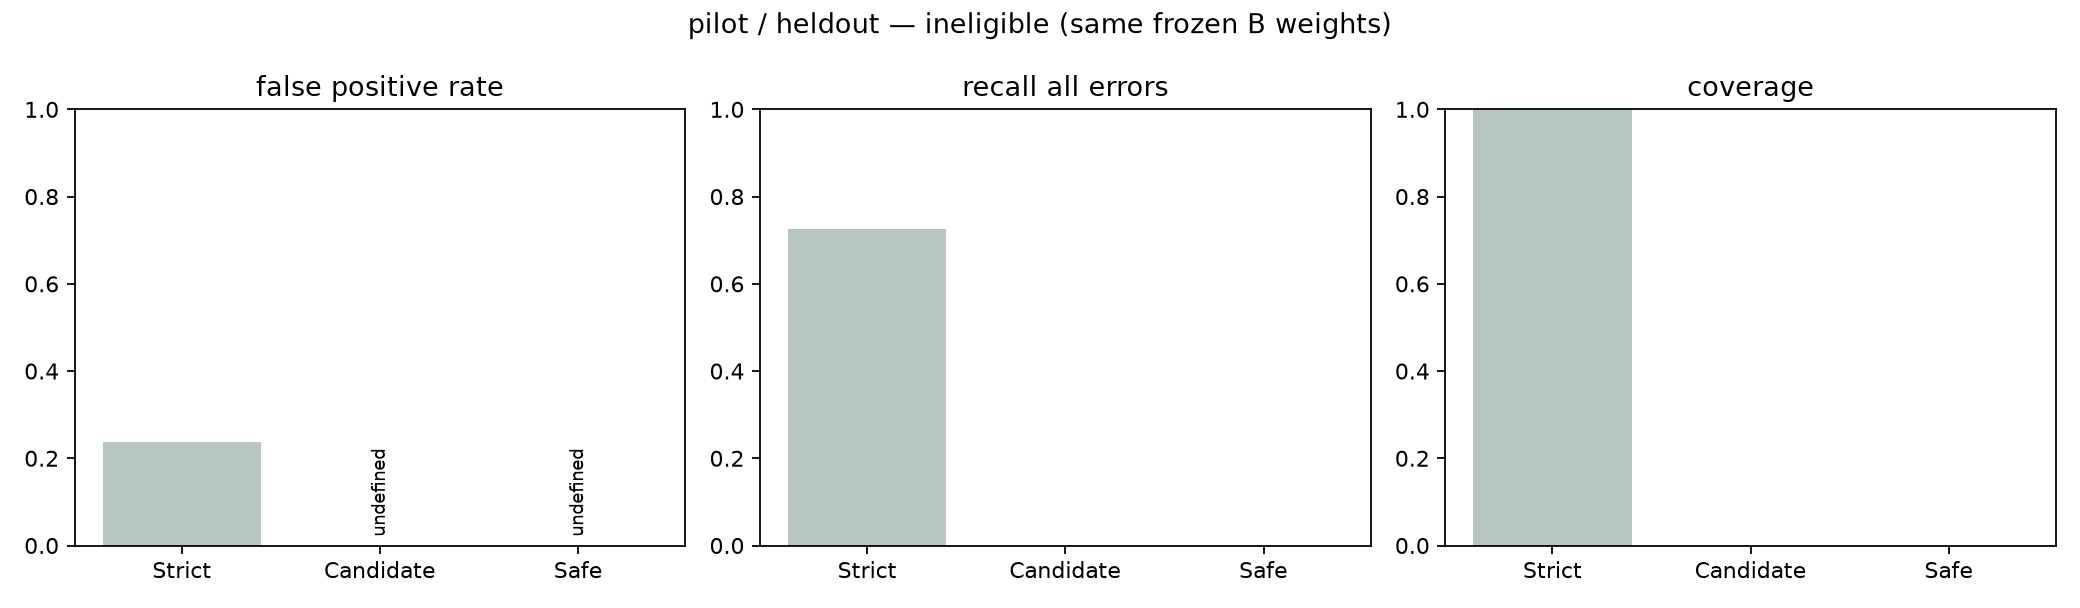

In [8]:
summary = experiment.read_json(OUTPUT/'report.json') if (OUTPUT/'report.json').exists() else None
if summary:
    columns = ['role','system','tp','fp','tn','fn','correct_abstained','error_abstained',
               'precision','recall_decided','recall_all_errors','false_positive_rate','false_negative_rate','coverage']
    display(pd.DataFrame(summary['metrics'])[columns])
    display(Image(filename=str(OUTPUT/'heldout_metrics.png')))
else:
    print('Pending report. Run the manual inference/calibration cells first.')

## 7. Phân bố score và coverage theo speaker

Score không phải xác suất; không diễn giải `0.8` thành “80% sai”. Uncertain bao gồm OOV, alignment không đủ bằng chứng, insert/delete chưa hỗ trợ và khoảng giữa hai ngưỡng.
Một speaker PNV chưa đủ chứng minh khả năng tổng quát giữa các giọng; test gốc vẫn để riêng.

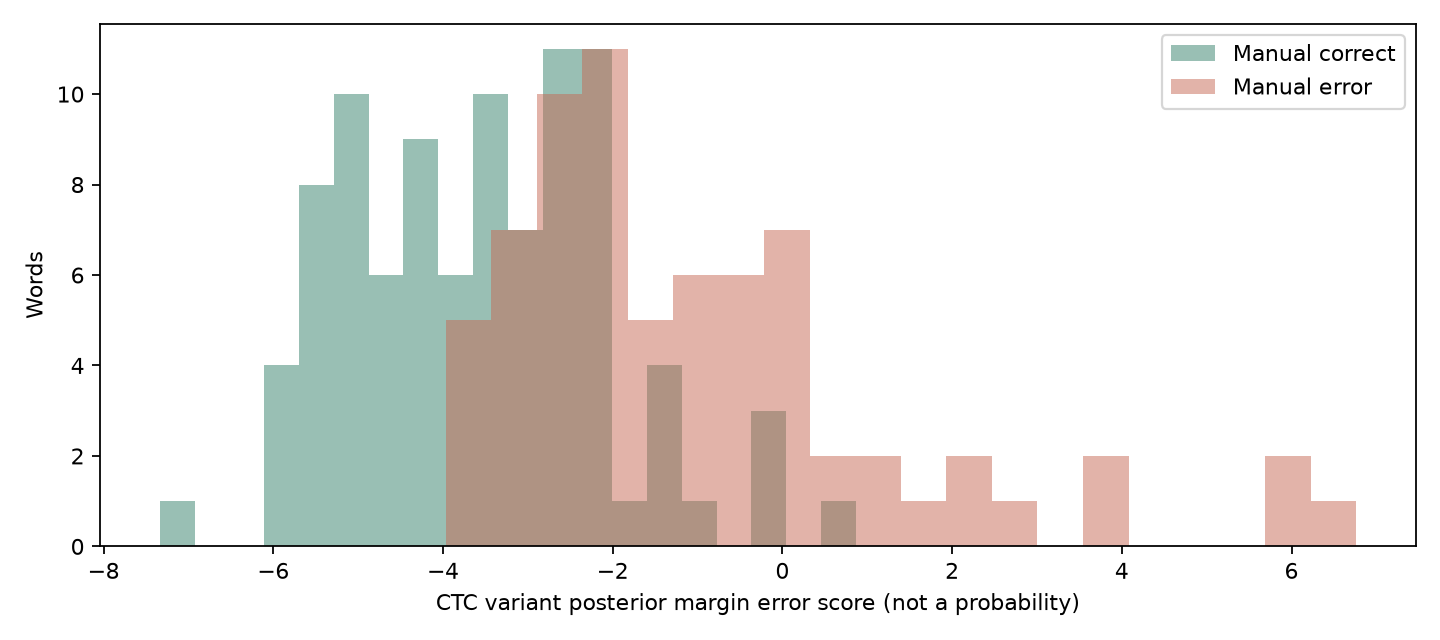

,speaker_id,total_words,gold_labelled_words,gold_unavailable_words,eligible_score_words,gold_correct,gold_error,decided_words,abstained_words,correct_abstained,...,false_positive_rate,false_negative_rate,false_rejection_rate,false_acceptance_rate,false_positive_all_correct,false_negative_all_errors,coverage,correct_coverage,error_coverage,f1_decided
0,HJK,95,95,0,71,61,34,0,95,61,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN
1,LXC,96,87,9,74,35,52,0,87,35,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN
2,PNV,192,192,0,163,97,95,0,192,97,...,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN


Ineligible / uncertain reasons:


reason
insertion_or_deletion_not_supported    64
reference_contains_unknown_words       11
Name: count, dtype: int64

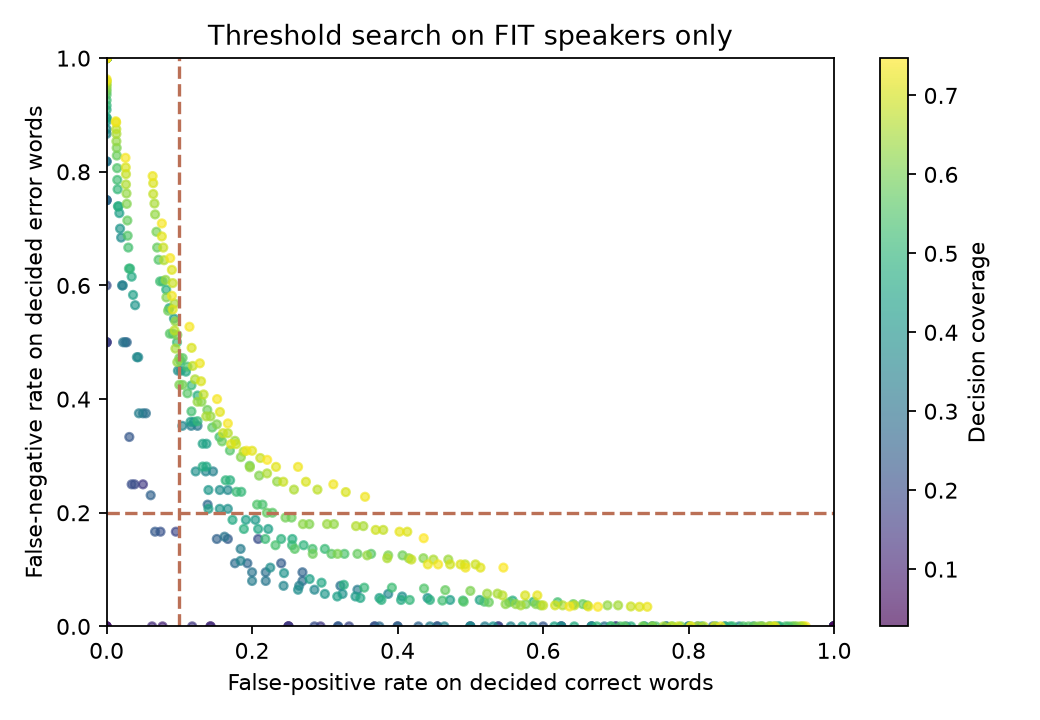

Mỗi điểm là một cặp ngưỡng trên FIT; hai đường đứt là giới hạn đã đăng ký, không phải ngưỡng được chỉnh từ heldout.


In [9]:
if (OUTPUT/'score_distributions.png').exists():
    display(Image(filename=str(OUTPUT/'score_distributions.png')))
    display(pd.read_csv(OUTPUT/'per_speaker.csv'))
    words = pd.read_csv(OUTPUT/'words.csv')
    print('Ineligible / uncertain reasons:')
    display(words.loc[~words['score_eligible'].fillna(False),'reason'].value_counts(dropna=False))
else:
    print('No score distribution yet.')
if (OUTPUT/'threshold_tradeoff.png').exists():
    display(Image(filename=str(OUTPUT/'threshold_tradeoff.png')))
    print('Mỗi điểm là một cặp ngưỡng trên FIT; hai đường đứt là giới hạn đã đăng ký, không phải ngưỡng được chỉnh từ heldout.')

## 8. Một output đầy đủ theo selection cố định

Score và lý do abstain giữ nguyên từ scorer. Nhãn đúng/sai chỉ được ghép vào bảng sau đó để chấm.
Không thay các lỗi model bằng lời giải thích mẫu và không bỏ các từ model không chấm được.

In [10]:
if (OUTPUT/'predictions.jsonl').exists():
    predictions = experiment.load_predictions(OUTPUT, plan)
    chosen = next(row for row in predictions if row['role']=='heldout')
    print(chosen['utterance_id'], chosen['reference_text'])
    print('Alignment:', chosen['scoring']['alignment'])
    table = pd.DataFrame(chosen['scoring']['words'])
    table['manual_word_error'] = chosen['gold_word_errors']
    display(table)
    print('Reference variants / target words:')
    display(chosen['scoring'].get('target_words', []))
else:
    print('No model output saved yet.')

PNV/arctic_a0127 It was a temptation but he resisted it
Alignment: {'status': 'aligned', 'score_eligible': True, 'approximate_timestamps': True, 'ctc_viterbi_log_prob': -12.498536436878567, 'greedy_gap_per_frame': 0.0477930191262015, 'greedy_phone_count': 28, 'reference_phone_count': 29, 'variant_compatible': False}


,index,text,status,error_score,score_eligible,reason,phone_scores,variant_compatible,start_sec,end_sec,manual_word_error
0,0,It,uncertain,-2.237677,True,reference_unconfirmed,"[{'phone': 'IH', 'phone_index': 0, 'margin': 2...",True,0.1204,0.1806,1
1,1,was,uncertain,-4.158017,True,reference_unconfirmed,"[{'phone': 'W', 'phone_index': 0, 'margin': 6....",True,0.2007,0.3813,0
2,2,a,uncertain,-7.335712,True,reference_unconfirmed,"[{'phone': 'AH', 'phone_index': 0, 'margin': 7...",True,0.4415,0.4817,0
3,3,temptation,uncertain,-4.288654,True,reference_unconfirmed,"[{'phone': 'T', 'phone_index': 0, 'margin': 5....",True,0.5017,1.1439,0
4,4,but,uncertain,-5.002507,True,reference_unconfirmed,"[{'phone': 'B', 'phone_index': 0, 'margin': 5....",True,1.6256,1.7460,0
5,5,he,uncertain,-5.443676,True,reference_unconfirmed,"[{'phone': 'HH', 'phone_index': 0, 'margin': 5...",True,1.8263,1.9868,0
6,6,resisted,uncertain,-3.012072,True,reference_unconfirmed,"[{'phone': 'R', 'phone_index': 0, 'margin': 4....",False,2.0872,2.6892,1
7,7,it,uncertain,-3.969237,False,insertion_or_deletion_not_supported,"[{'phone': 'IH', 'phone_index': 0, 'margin': 3...",False,2.7896,2.8699,0


Reference variants / target words:


[{'text': 'It',
  'phones': ['IH', 'T'],
  'pronunciation_phones': ['IH1', 'T'],
  'dictionary_variant_index': 0,
  'dictionary_variant_count': 1},
 {'text': 'was',
  'phones': ['W', 'AH', 'Z'],
  'pronunciation_phones': ['W', 'AH0', 'Z'],
  'dictionary_variant_index': 1,
  'dictionary_variant_count': 2},
 {'text': 'a',
  'phones': ['AH'],
  'pronunciation_phones': ['AH0'],
  'dictionary_variant_index': 0,
  'dictionary_variant_count': 2},
 {'text': 'temptation',
  'phones': ['T', 'EH', 'M', 'T', 'EY', 'SH', 'AH', 'N'],
  'pronunciation_phones': ['T', 'EH0', 'M', 'T', 'EY1', 'SH', 'AH0', 'N'],
  'dictionary_variant_index': 0,
  'dictionary_variant_count': 1},
 {'text': 'but',
  'phones': ['B', 'AH', 'T'],
  'pronunciation_phones': ['B', 'AH1', 'T'],
  'dictionary_variant_index': 0,
  'dictionary_variant_count': 1},
 {'text': 'he',
  'phones': ['HH', 'IY'],
  'pronunciation_phones': ['HH', 'IY1'],
  'dictionary_variant_index': 0,
  'dictionary_variant_count': 1},
 {'text': 'resisted',
 

## 9. Pilot và đủ 450 validation, cùng phương pháp và policy đã khóa

Full validation mở rộng số audio fit/audit theo cùng phân nhóm speaker, không thay công thức score hoặc nới ngưỡng FPR/FNR sau khi xem pilot.
Đây vẫn là development audit; không gọi 450 validation là test độc lập. Nếu cả hai không có cặp ngưỡng đạt, kết luận là chưa đủ bằng chứng để bật chấm đúng/sai.

,mode,utterances,status,heldout_gold_correct,heldout_gold_error,strict_FP,strict_FPR,strict_recall,safe_coverage,failures
0,pilot,40,ineligible,97,95,23,0.237113,0.726316,0.0,[no_threshold_meets_fit_policy]
1,full-validation,450,ineligible,720,669,168,0.234637,0.696562,0.0,[no_threshold_meets_fit_policy]


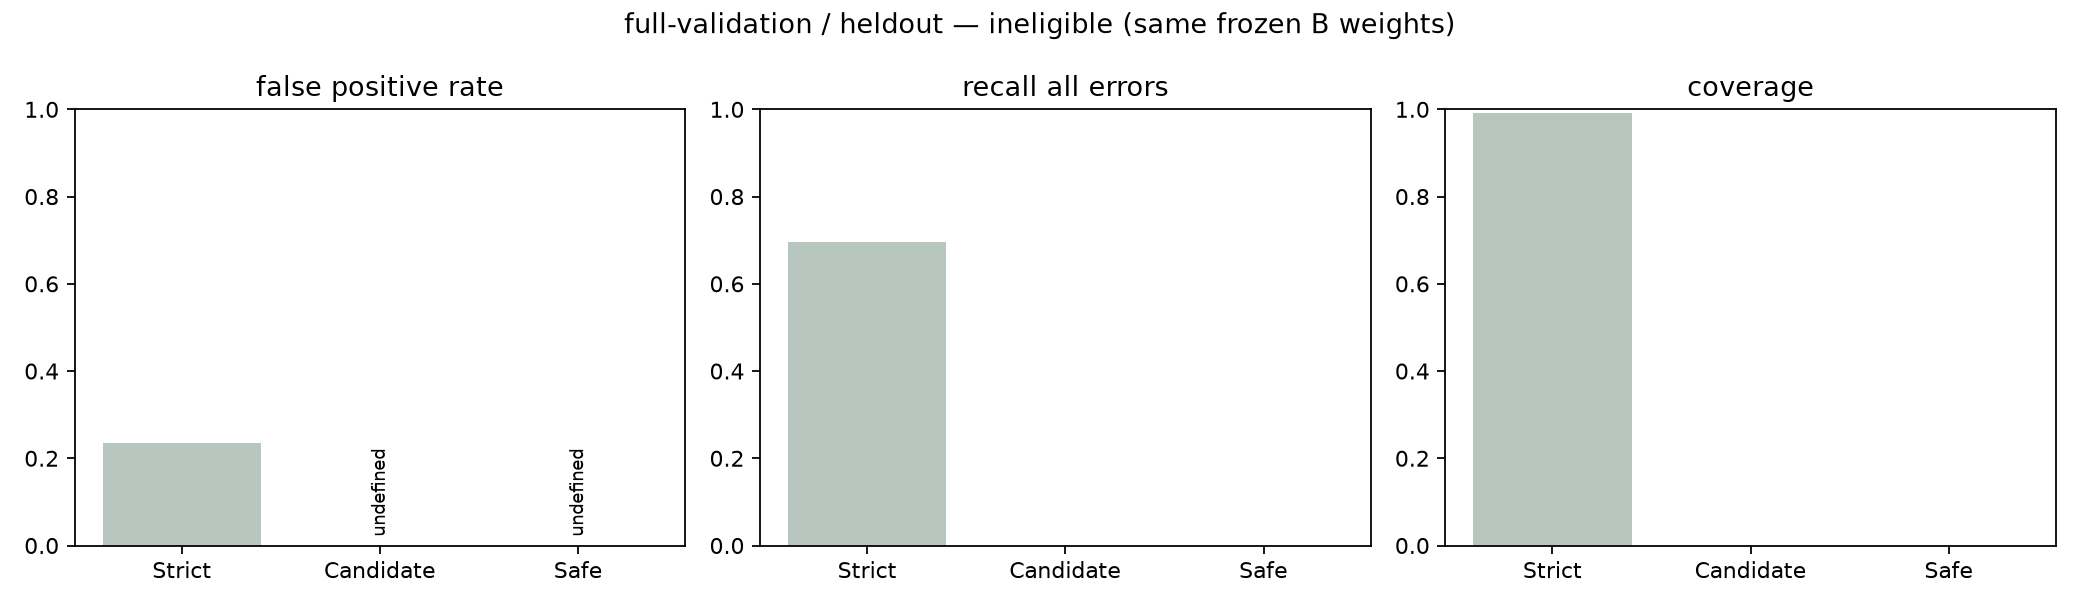

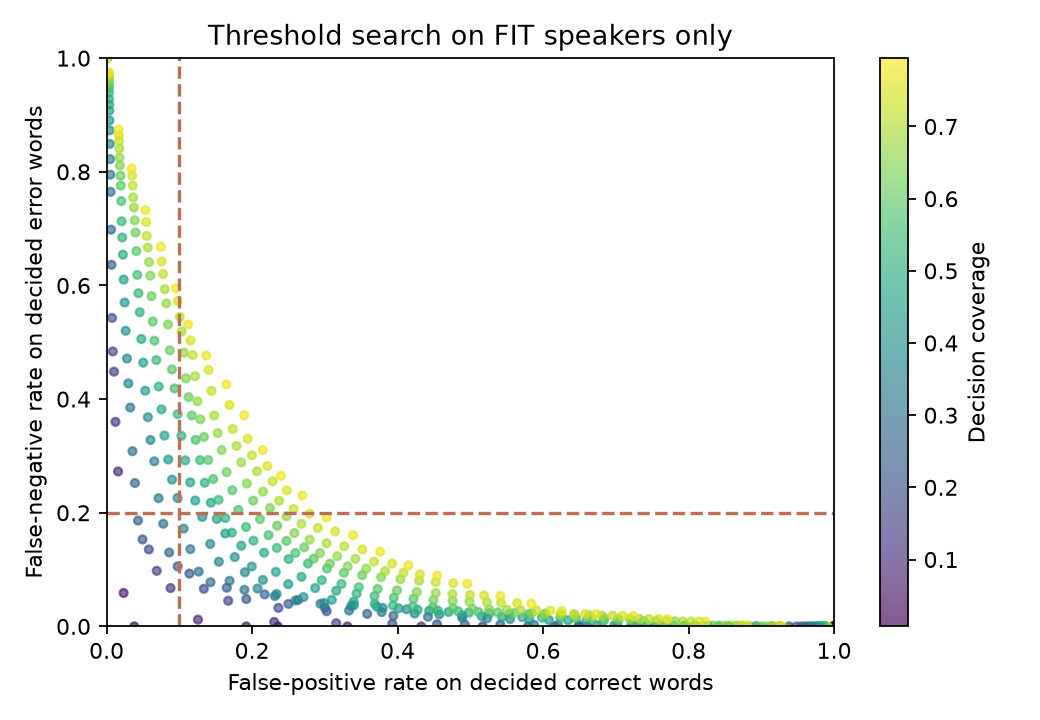

In [11]:
comparison = []
for mode in ['pilot','full-validation']:
    path = ROOT/CONFIG['output_root']/mode/'report.json'
    if not path.exists(): continue
    value = experiment.read_json(path)
    strict = next(row for row in value['metrics'] if row['role']=='heldout' and row['system']=='strict_greedy_single_CMU')
    safe = next(row for row in value['metrics'] if row['role']=='heldout' and row['system']=='safe_verified_policy')
    comparison.append({'mode': mode, 'utterances': value['utterances'], 'status': value['artifact_status'],
                       'heldout_gold_correct': strict['gold_correct'], 'heldout_gold_error': strict['gold_error'],
                       'strict_FP': strict['fp'], 'strict_FPR': strict['false_positive_rate'],
                       'strict_recall': strict['recall_all_errors'], 'safe_coverage': safe['coverage'],
                       'failures': value['validation']['failures']})
display(pd.DataFrame(comparison))
full = ROOT/CONFIG['output_root']/'full-validation'
if (full/'heldout_metrics.png').exists():
    display(Image(filename=str(full/'heldout_metrics.png')))
    display(Image(filename=str(full/'threshold_tradeoff.png')) if (full/'threshold_tradeoff.png').exists() else 'Fit search plot pending')

## 10. Chạy đủ validation hoặc test sau khi khóa artifact

Full validation = 300 HJK/LXC fit + 150 PNV audit. Test = 900 speaker khác, chỉ đánh giá bằng artifact eligible đã khóa, không refit.
SpeechOcean test không dùng chọn ngưỡng và không được gọi từ notebook này. Các lệnh dưới chỉ được in ra, không tự chạy.

In [12]:
print(f'"{PYTHON}" -u scripts/experiment_pronunciation_calibration.py --full-validation --run')
print(f'"{PYTHON}" -u scripts/experiment_pronunciation_calibration.py --test --run '
      '--frozen-calibration data/generated/pronunciation-calibration-v1/full-validation/calibration.json')
print('Test is blocked if the artifact is ineligible or checkpoint/CMU/vocabulary/method hashes differ.')

"D:\NCC\MDD\.venv\Scripts\python.exe" -u scripts/experiment_pronunciation_calibration.py --full-validation --run
"D:\NCC\MDD\.venv\Scripts\python.exe" -u scripts/experiment_pronunciation_calibration.py --test --run --frozen-calibration data/generated/pronunciation-calibration-v1/full-validation/calibration.json
Test is blocked if the artifact is ineligible or checkpoint/CMU/vocabulary/method hashes differ.


## 11. File kết quả và giới hạn

`selection.json`, `predictions.jsonl`, `calibration.json`, `metrics.csv`, `words.csv`, `per_speaker.csv`, PNG và `report.html` được lưu riêng.
Đây là thử nghiệm chấm điểm/hiệu chỉnh trên trọng số B hiện có, **không phải train model mới** và chưa chứng minh mức phát âm đạt chuẩn người bản ngữ.

In [13]:
for item in CONFIG['limitations']: print('•', item)
print('HTML report:', OUTPUT/'report.html')
print('Calibration artifact:', OUTPUT/'calibration.json')
print('Notebook HTML export:', OUTPUT/'mdd_pronunciation_calibration.html')

• The frozen B checkpoint was selected using all 450 validation utterances. PNV is held out from threshold fitting, not from earlier checkpoint selection.
• Shared read prompts across speakers follow the existing protocol; this is not a prompt-disjoint experiment.
• Gold labels are manual L2-ARCTIC phone annotations. GPT-generated L2-Arctic-plus feedback text is not used as an acoustic label.
• Pilot results are exploratory. One held-out speaker cannot establish robustness across accents or natural conversation.
• This compares scoring/calibration on the same frozen weights, not a new before/after neural-training result.
• The original 900 test utterances and SpeechOcean test remain outside calibration and default inference.
HTML report: D:\NCC\MDD\data\generated\pronunciation-calibration-v1\pilot\report.html
Calibration artifact: D:\NCC\MDD\data\generated\pronunciation-calibration-v1\pilot\calibration.json
Notebook HTML export: D:\NCC\MDD\data\generated\pronunciation-calibration-v1\pi